# Feature Engineering and Modelling

---

1. Import packages
2. Load data
3. Modelling

---

## 1. Import packages

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
# --- STEP 1: ENVIRONMENT SETUP & DATA LOADING ---

# Import necessary libraries for modeling and evaluation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score, roc_curve

# Set visual styling
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
pd.set_option('display.max_columns', None)

---
## 2. Load data

In [3]:
# Load the final prediction dataset provided by Estelle
df_predictions = pd.read_csv('data_for_predictions.csv')

# Inspect dataset shape and columns
print("=== Dataset Overview ===")
print(f"Dataset Shape (Rows, Columns): {df_predictions.shape}")
print("\nColumn Names:")
print(df_predictions.columns.tolist())

# Inspect target distribution (churn)
print("\n=== Target Distribution (Churn) ===")
churn_counts = df_predictions['churn'].value_counts()
churn_pct = df_predictions['churn'].value_counts(normalize=True) * 100

for val, count in churn_counts.items():
    pct = churn_pct[val]
    print(f"Churn Status {val}: {count} customers ({pct:.2f}%)")

# Preview the first few rows
print("\n=== Data Preview ===")
display(df_predictions.head(3))

=== Dataset Overview ===
Dataset Shape (Rows, Columns): (14606, 64)

Column Names:
['Unnamed: 0', 'id', 'cons_12m', 'cons_gas_12m', 'cons_last_month', 'forecast_cons_12m', 'forecast_discount_energy', 'forecast_meter_rent_12m', 'forecast_price_energy_off_peak', 'forecast_price_energy_peak', 'forecast_price_pow_off_peak', 'has_gas', 'imp_cons', 'margin_gross_pow_ele', 'margin_net_pow_ele', 'nb_prod_act', 'net_margin', 'pow_max', 'var_year_price_off_peak_var', 'var_year_price_peak_var', 'var_year_price_mid_peak_var', 'var_year_price_off_peak_fix', 'var_year_price_peak_fix', 'var_year_price_mid_peak_fix', 'var_year_price_off_peak', 'var_year_price_peak', 'var_year_price_mid_peak', 'var_6m_price_off_peak_var', 'var_6m_price_peak_var', 'var_6m_price_mid_peak_var', 'var_6m_price_off_peak_fix', 'var_6m_price_peak_fix', 'var_6m_price_mid_peak_fix', 'var_6m_price_off_peak', 'var_6m_price_peak', 'var_6m_price_mid_peak', 'churn', 'offpeak_diff_dec_january_energy', 'offpeak_diff_dec_january_power',

,Unnamed: 0,id,cons_12m,cons_gas_12m,cons_last_month,forecast_cons_12m,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_off_peak,forecast_price_energy_peak,forecast_price_pow_off_peak,has_gas,imp_cons,margin_gross_pow_ele,margin_net_pow_ele,nb_prod_act,net_margin,pow_max,var_year_price_off_peak_var,var_year_price_peak_var,var_year_price_mid_peak_var,var_year_price_off_peak_fix,var_year_price_peak_fix,var_year_price_mid_peak_fix,var_year_price_off_peak,var_year_price_peak,var_year_price_mid_peak,var_6m_price_off_peak_var,var_6m_price_peak_var,var_6m_price_mid_peak_var,var_6m_price_off_peak_fix,var_6m_price_peak_fix,var_6m_price_mid_peak_fix,var_6m_price_off_peak,var_6m_price_peak,var_6m_price_mid_peak,churn,offpeak_diff_dec_january_energy,offpeak_diff_dec_january_power,off_peak_peak_var_mean_diff,peak_mid_peak_var_mean_diff,off_peak_mid_peak_var_mean_diff,off_peak_peak_fix_mean_diff,peak_mid_peak_fix_mean_diff,off_peak_mid_peak_fix_mean_diff,off_peak_peak_var_max_monthly_diff,peak_mid_peak_var_max_monthly_diff,off_peak_mid_peak_var_max_monthly_diff,off_peak_peak_fix_max_monthly_diff,peak_mid_peak_fix_max_monthly_diff,off_peak_mid_peak_fix_max_monthly_diff,tenure,months_activ,months_to_end,months_modif_prod,months_renewal,channel_MISSING,channel_ewpakwlliwisiwduibdlfmalxowmwpci,channel_foosdfpfkusacimwkcsosbicdxkicaua,channel_lmkebamcaaclubfxadlmueccxoimlema,channel_usilxuppasemubllopkaafesmlibmsdf,origin_up_kamkkxfxxuwbdslkwifmmcsiusiuosws,origin_up_ldkssxwpmemidmecebumciepifcamkci,origin_up_lxidpiddsbxsbosboudacockeimpuepw
0,0,24011ae4ebbe3035111d65fa7c15bc57,0.000000,4.739944,0.0,0.000000,0.0,0.444045,0.114481,0.098142,40.606701,1,0.0,25.44,25.44,2,678.99,43.648,0.000061,2.627605e-05,0.00044,1.102785,49.550703,22.022535,1.102846,4.955073e+01,22.022975,0.000131,4.100838e-05,0.000908,2.086294,99.530517,44.235794,2.086425,9.953056e+01,44.236702,1,0.020057,3.700961,0.024038,0.034219,0.058257,18.590255,7.45067,26.040925,0.060550,0.085483,0.146033,44.26693,8.145775,44.26693,3,30,5,2,6,0,0,1,0,0,0,0,1
1,1,d29c2c54acc38ff3c0614d0a653813dd,3.668479,0.000000,0.0,2.280920,0.0,1.237292,0.145711,0.000000,44.311378,0,0.0,16.38,16.38,1,18.89,13.800,0.000005,6.089453e-04,0.00000,0.006465,0.000000,0.000000,0.006470,6.089453e-04,0.000000,0.000003,1.217891e-03,0.000000,0.009482,0.000000,0.000000,0.009485,1.217891e-03,0.000000,0,-0.003767,0.177779,0.142485,0.007124,0.149609,44.311375,0.00000,44.311375,0.151367,0.085483,0.151367,44.44471,0.000000,44.44471,7,76,7,76,4,1,0,0,0,0,1,0,0
2,2,764c75f661154dac3a6c254cd082ea7d,2.736397,0.000000,0.0,1.689841,0.0,1.599009,0.165794,0.087899,44.311378,0,0.0,28.60,28.60,1,6.60,13.856,0.000006,2.558511e-07,0.00000,0.007662,0.000000,0.000000,0.007668,2.558511e-07,0.000000,0.000004,9.450150e-08,0.000000,0.000000,0.000000,0.000000,0.000004,9.450150e-08,0.000000,0,-0.004670,0.177779,0.082090,0.088421,0.170512,44.385450,0.00000,44.385450,0.084587,0.089162,0.172468,44.44471,0.000000,44.44471,6,68,3,68,8,0,0,1,0,0,1,0,0


---

## 3. Modelling

### Data Preparation & Train-Test Split

In [4]:
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

In [5]:
# --- STEP 2: DATA PREPARATION & TRAIN-TEST SPLIT ---

# 1. Separate features (X) from the target variable (y, which is 'churn')
# Drop 'id' (identifier) and 'churn' (target) from the feature set
cols_to_drop = ['churn']
if 'id' in df_predictions.columns:
    cols_to_drop.append('id')

X = df_predictions.drop(columns=cols_to_drop)
y = df_predictions['churn']

# 2. Handle any remaining categorical variables via one-hot encoding
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
if len(categorical_cols) > 0:
    print(f"Encoding categorical columns: {categorical_cols}")
    X = pd.get_dummies(X, columns=categorical_cols, drop_first=True)
else:
    print("No categorical columns remaining; all features are numerical.")

# 3. Split the data into training (80%) and testing (20%) sets
# stratify=y ensures that the proportion of churned customers is preserved in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("\n=== Train-Test Split Summary ===")
print(f"Training Features Shape (X_train): {X_train.shape}")
print(f"Testing Features Shape (X_test): {X_test.shape}")
print(f"Training Target Shape (y_train): {y_train.shape}")
print(f"Testing Target Shape (y_test): {y_test.shape}")

No categorical columns remaining; all features are numerical.

=== Train-Test Split Summary ===
Training Features Shape (X_train): (11684, 62)
Testing Features Shape (X_test): (2922, 62)
Training Target Shape (y_train): (11684,)
Testing Target Shape (y_test): (2922,)


### Training the Random Forest Classifier

In [6]:
# --- STEP 3: TRAINING THE RANDOM FOREST CLASSIFIER ---

# 1. Initialize the Random Forest Classifier
# n_estimators=100 builds 100 decision trees, random_state ensures reproducibility, n_jobs=-1 utilizes all CPU cores
rf_model = RandomForestClassifier(
    n_estimators=100, 
    random_state=42, 
    n_jobs=-1
)

# 2. Train (fit) the model on the training data
print("Training the Random Forest classifier...")
rf_model.fit(X_train, y_train)

print("✓ Model training completed successfully!")

Training the Random Forest classifier...
✓ Model training completed successfully!


### Model Evaluation & Metrics Analysis

=== Performance Summary ===
Accuracy Score: 0.9086
ROC-AUC Score:  0.6920

=== Confusion Matrix ===
[[2633    5]
 [ 262   22]]

=== Classification Report ===
              precision    recall  f1-score   support

           0       0.91      1.00      0.95      2638
           1       0.81      0.08      0.14       284

    accuracy                           0.91      2922
   macro avg       0.86      0.54      0.55      2922
weighted avg       0.90      0.91      0.87      2922



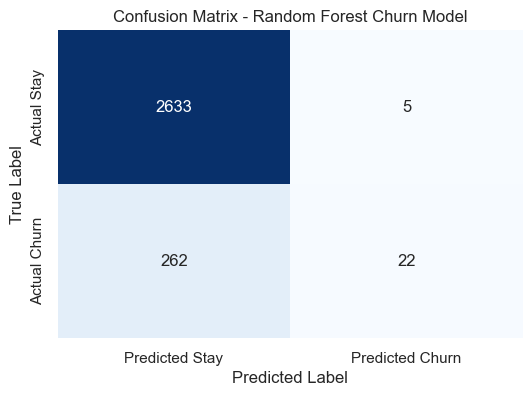

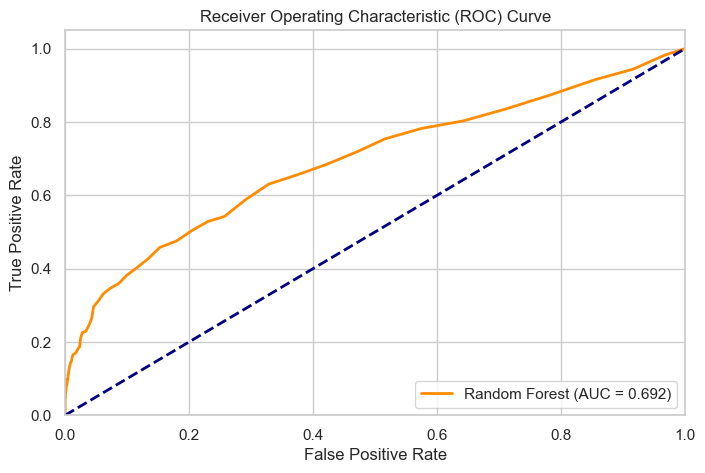

In [7]:
# --- STEP 4: MODEL EVALUATION & METRICS ANALYSIS ---

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Generate predictions on the test set
y_pred = rf_model.predict(X_test)
y_pred_proba = rf_model.predict_proba(X_test)[:, 1] # Probability of churning (class 1)

# 2. Calculate core metrics
acc = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print(f"=== Performance Summary ===")
print(f"Accuracy Score: {acc:.4f}")
print(f"ROC-AUC Score:  {roc_auc:.4f}")

print("\n=== Confusion Matrix ===")
print(conf_matrix)

print("\n=== Classification Report ===")
print(class_report)

# 3. Plot Confusion Matrix for visual presentation
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Stay', 'Predicted Churn'],
            yticklabels=['Actual Stay', 'Actual Churn'])
plt.title('Confusion Matrix - Random Forest Churn Model')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# 4. Plot ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, label=f'Random Forest (AUC = {roc_auc:.3f})', color='darkorange', lw=2)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

### Extracting Feature Importances

=== Top 10 Most Important Features for Predicting Churn ===


,Feature,Importance
0,Unnamed: 0,0.047845
6,forecast_meter_rent_12m,0.047366
1,cons_12m,0.047064
15,net_margin,0.044595
12,margin_gross_pow_ele,0.044272
4,forecast_cons_12m,0.043608
13,margin_net_pow_ele,0.043447
3,cons_last_month,0.035115
16,pow_max,0.033255
50,months_activ,0.030138


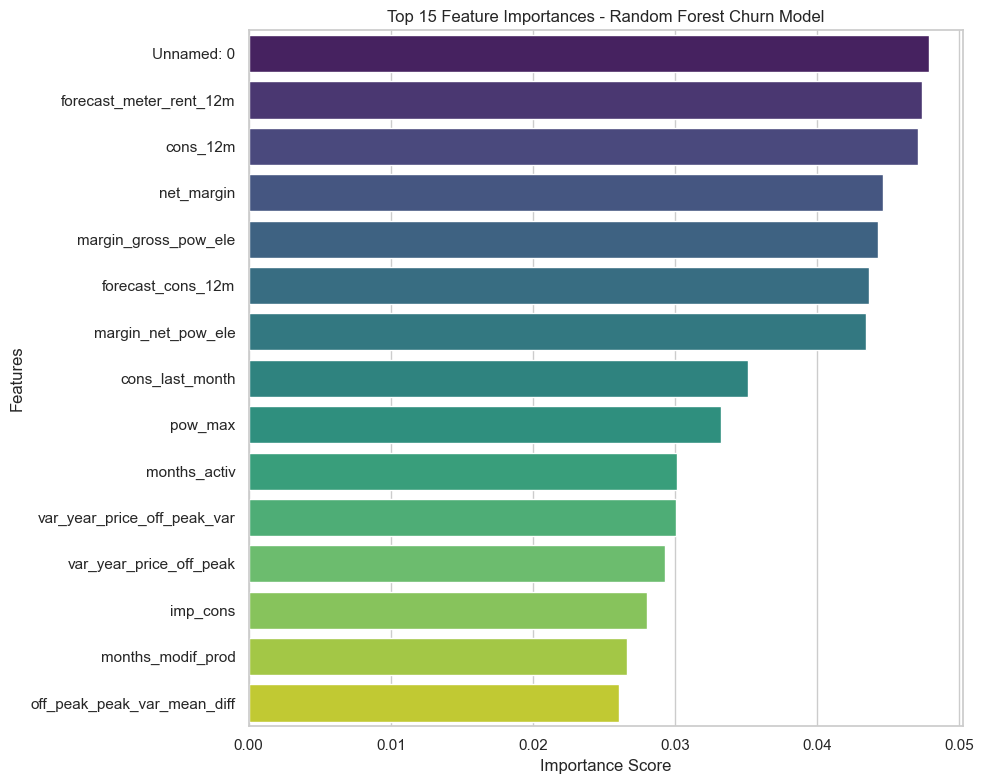

In [8]:
# --- STEP 5: FEATURE IMPORTANCE ANALYSIS ---

# 1. Extract feature importances from the trained Random Forest model
importances = rf_model.feature_importances_
feature_names = X_train.columns

# Create a DataFrame for visualization
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print("=== Top 10 Most Important Features for Predicting Churn ===")
display(feature_importance_df.head(10))

# 2. Plot Top 15 Feature Importances
plt.figure(figsize=(10, 8))
sns.barplot(
    x='Importance', 
    y='Feature', 
    data=feature_importance_df.head(15), 
    palette='viridis', 
    hue='Feature', 
    legend=False
)
plt.title('Top 15 Feature Importances - Random Forest Churn Model')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()